In [47]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Carga de los datos

In [80]:
# Cargar los datos
csv_file_path = r"../../data/limpieza/cleaned_data.csv"  # Ajusta la ruta si es necesario
df = pd.read_csv(csv_file_path)

#No usar las tendencias futuras, ni los indices ya que no aporta información al modelo
vars_validas = [v for v in df.columns if v not in ['tendencia_futura_7d', 'tendencia_futura_30d', 'Unnamed: 0', 'timestamp']]

df = df[vars_validas]

# Análisis de la correlación a 7 días

**Objetivo del análisis**:
El objetivo principal de este análisis es construir un conjunto de variables explicativas robusto y sin redundancia para predecir la variable objetivo pct_cambio_7d, que representa el cambio porcentual del precio del Bitcoin a 7 días. Para ello, hemos realizado un proceso cuidadoso de selección de variables, eliminando aquellas con alta colinealidad y manteniendo la mayor cantidad posible de información útil y relevante.

## Vistazo inicial con todas las variables

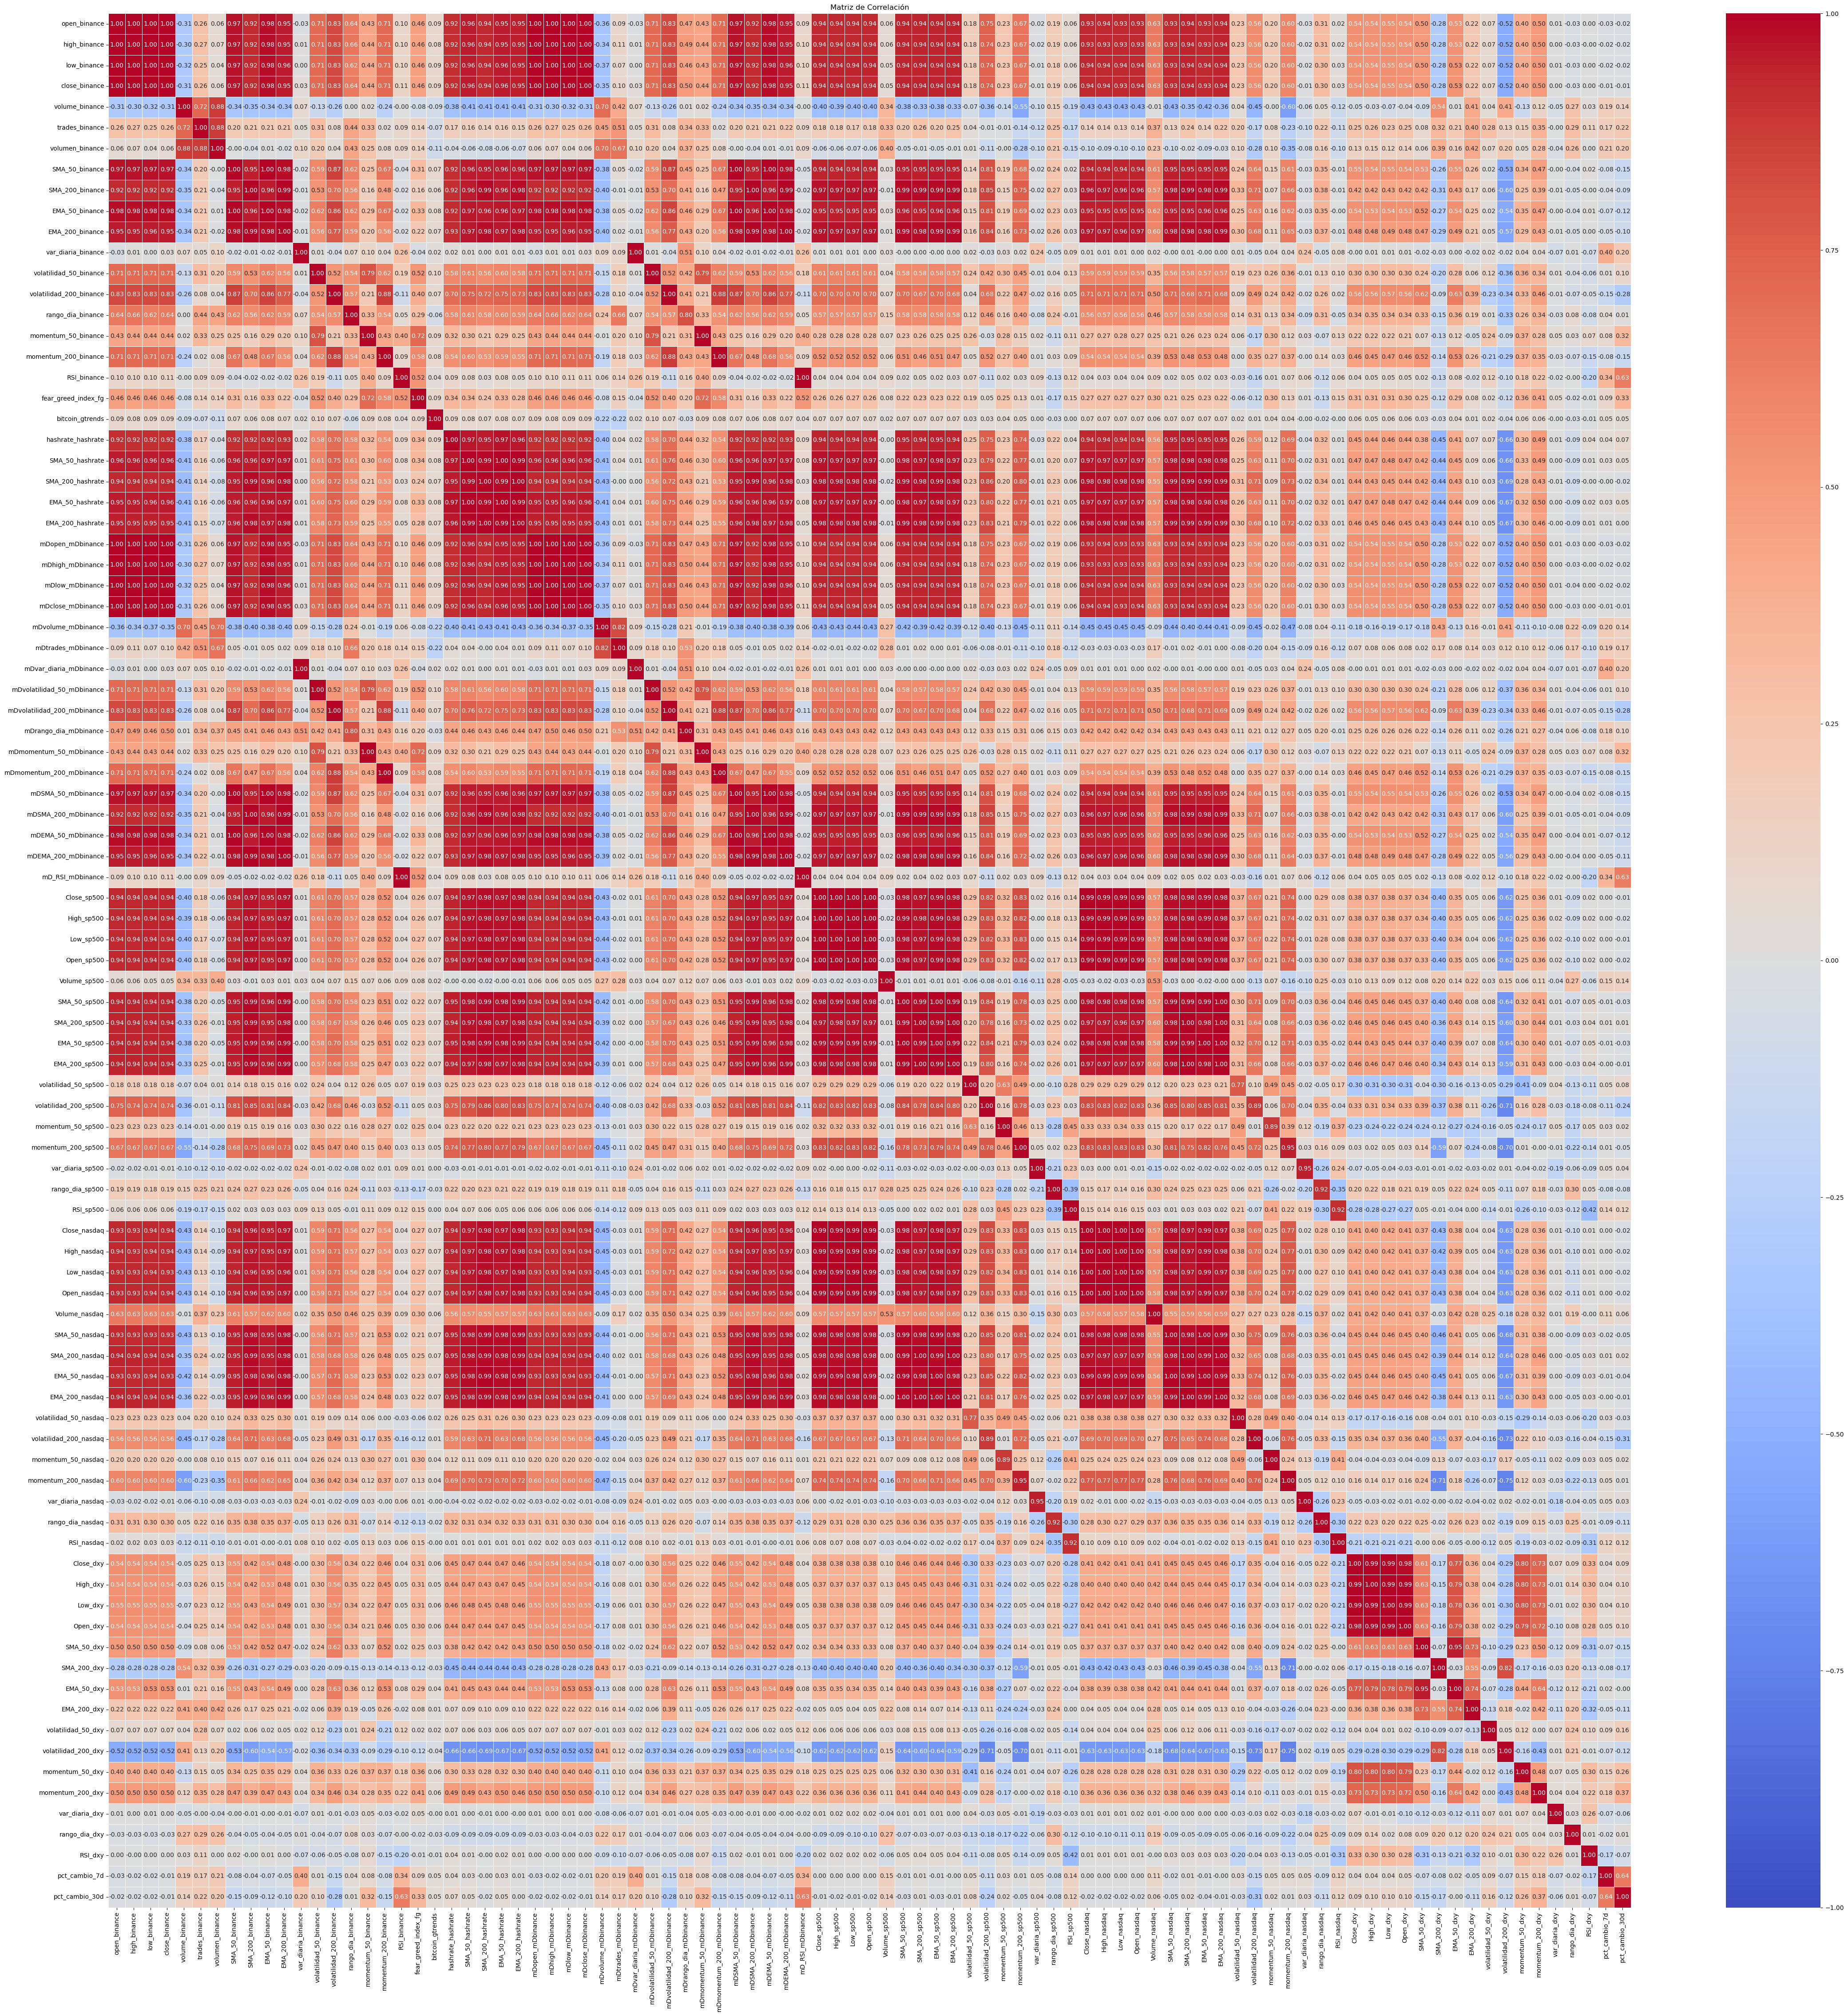

In [54]:
# Calcular la matriz de correlación
corr = df.corr()

# Ajustar tamaño del gráfico dinámicamente
fig_width = max(12, len(corr.columns) * 0.5)
fig_height = max(12, len(corr.columns) * 0.5)

# Graficar heatmap completo
plt.figure(figsize=(fig_width, fig_height))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f",
            linewidths=0.5, cbar=True, center=0, vmin=-1, vmax=1)

# Estética
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.title("Matriz de Correlación")

plt.tight_layout()
plt.show()

**Observación**: Al explorar el conjunto de datos, podemos detectar un alto grado de correlación entre muchas variables predictoras, especialmente dentro de grupos que representan fenómenos similares (por ejemplo, precios diarios o medias móviles). Por ello decidimos eliminar variables del conjunto de datos para evitar esta autocorrelación.

## Estrategia 1: Eliminación mecánica por correlación

### Selección de las variables altamente correlacionadas

In [86]:
import numpy as np

# Crear la matriz de correlación sin incluir las variables respuesta
corr_matrix = df.iloc[:, :-2].corr().abs()

# Seleccionar variables con correlación > 0.9
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Encuentra las columnas que tienen una correlación mayor a 0.9
variables_a_eliminar = [column for column in upper_tri.columns if any(upper_tri[column] > 0.9)]
print(f"Variables eliminadas por alta correlación: {variables_a_eliminar}")

# Escoger las variables que no tengan una correlacion mayor a 0.9
variables_predictoras = [col for col in df.columns if col not in variables_a_eliminar]
print(f"Variables resultantes: {list(variables_predictoras)}")

Variables eliminadas por alta correlación: ['high_binance', 'low_binance', 'close_binance', 'SMA_50_binance', 'SMA_200_binance', 'EMA_50_binance', 'EMA_200_binance', 'hashrate_hashrate', 'SMA_50_hashrate', 'SMA_200_hashrate', 'EMA_50_hashrate', 'EMA_200_hashrate', 'mDopen_mDbinance', 'mDhigh_mDbinance', 'mDlow_mDbinance', 'mDclose_mDbinance', 'mDvar_diaria_mDbinance', 'mDvolatilidad_50_mDbinance', 'mDvolatilidad_200_mDbinance', 'mDmomentum_50_mDbinance', 'mDmomentum_200_mDbinance', 'mDSMA_50_mDbinance', 'mDSMA_200_mDbinance', 'mDEMA_50_mDbinance', 'mDEMA_200_mDbinance', 'mD_RSI_mDbinance', 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'SMA_50_sp500', 'SMA_200_sp500', 'EMA_50_sp500', 'EMA_200_sp500', 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'SMA_50_nasdaq', 'SMA_200_nasdaq', 'EMA_50_nasdaq', 'EMA_200_nasdaq', 'momentum_200_nasdaq', 'var_diaria_nasdaq', 'rango_dia_nasdaq', 'RSI_nasdaq', 'High_dxy', 'Low_dxy', 'Open_dxy', 'EMA_50_dxy']
Variables resultantes: [

### Visualización de las correlaciones con el nuevo conjunto de variables

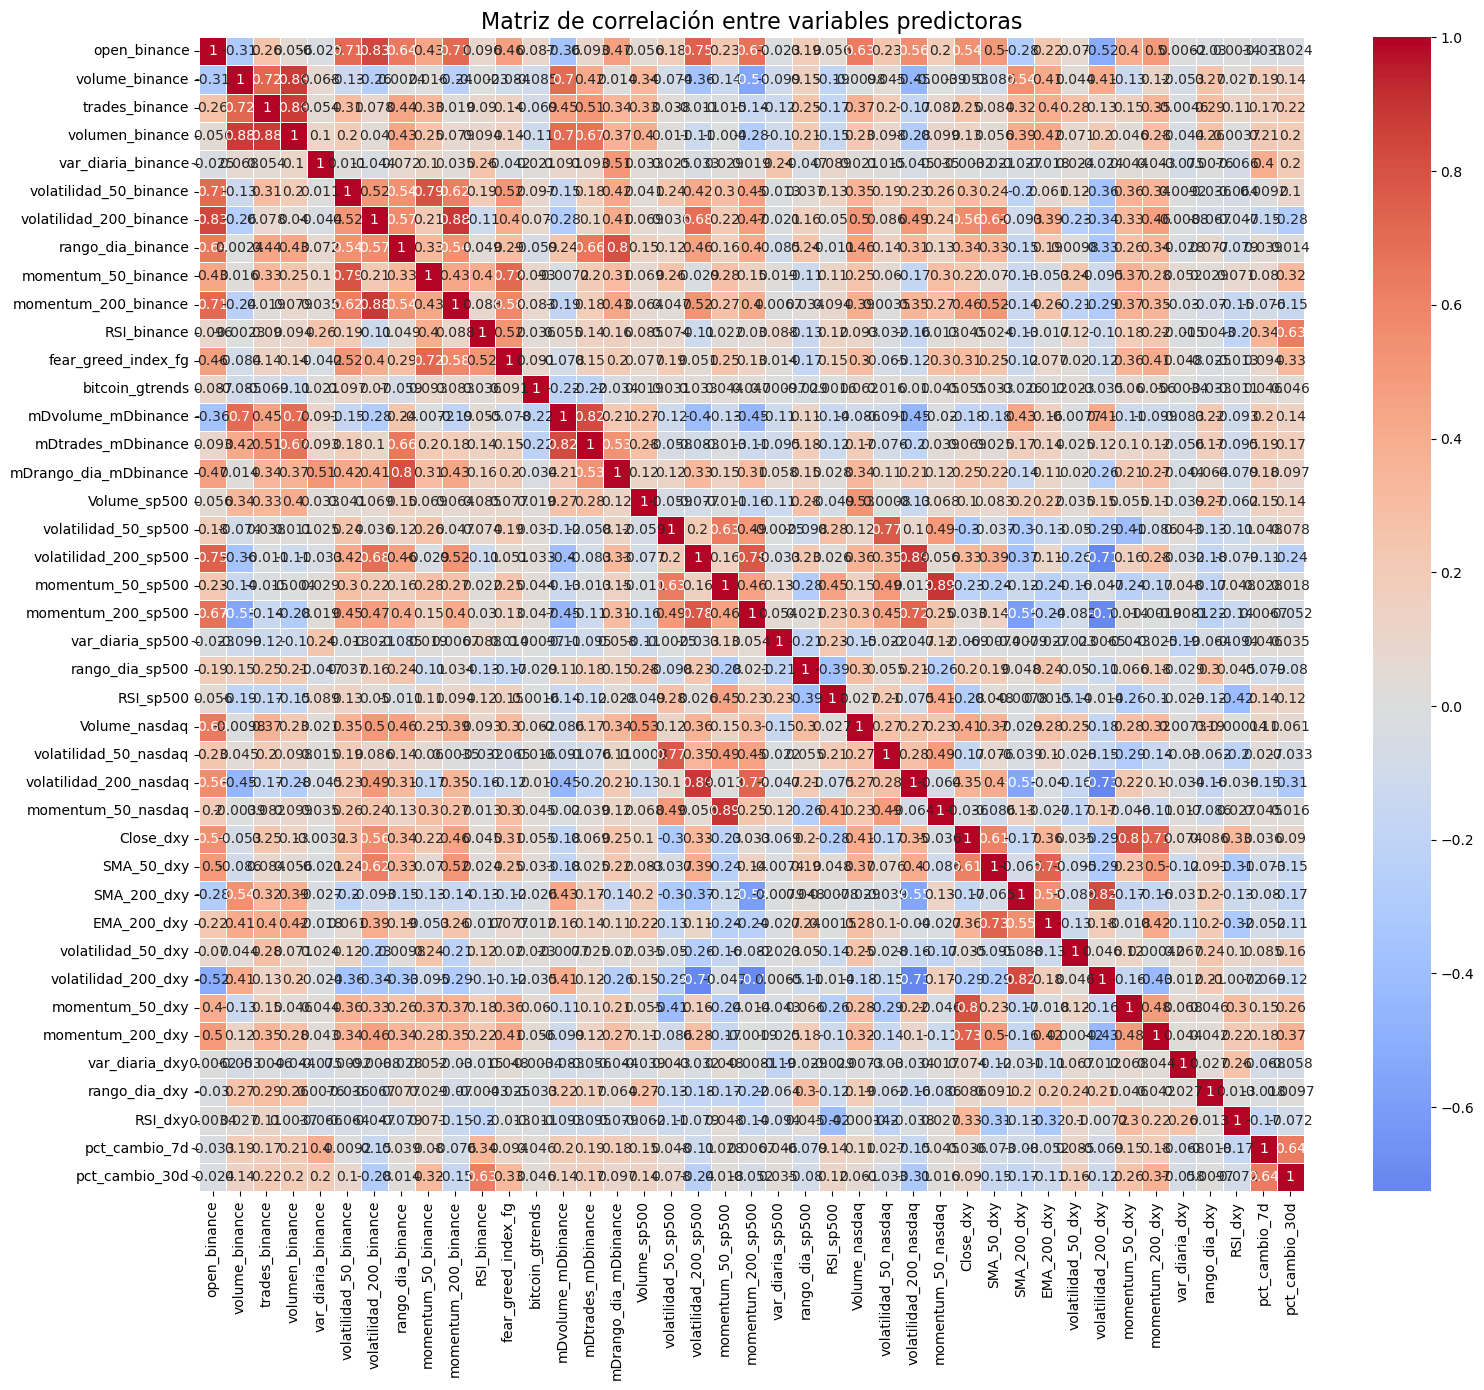

In [92]:
# Calcular matriz de correlación
corr_matrix = df[variables_predictoras].corr()

# Dibujar heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de correlación entre variables predictoras', fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Análisis**: Para eliminar esta autocorrelación, se identificaron pares de variables con una correlación absoluta superior a 0.9 y se eliminó una de cada par de forma sistemática. Este procedimiento permitió reducir la colinealidad entre variables y simplificar el conjunto de datos. Sin embargo, al revisar manualmente las variables restantes, se evidenció que muchas de las eliminadas aportaban información clave para comprender la dinámica del mercado. En algunos casos, el enfoque automático eliminaba todas las variables pertenecientes a una misma familia de indicadores, como las medias móviles asociadas al precio del bitcoin, dejando al conjunto de datos sin ningún representante de esa dimensión analítica, y comprometiendo así la diversidad informativa del modelo. Así, quedó claro que el enfoque mecánico, aunque útil desde el punto de vista estadístico, no diferenciaba entre redundancia técnica y valor analítico. Esta limitación motivó un replanteamiento de la estrategia, buscando un enfoque más reflexivo que equilibrara la reducción de redundancias con la conservación del contenido informativo más relevante.